# Background cutflow

Run this notebook on LPC using the same Python environment as `Cutflow_COFFEA_RUN.ipynb`. It reads the existing output; it does not rerun event processing.

The plot shows the **total expected background yield** after each cumulative cut, not raw simulated counts. The all-events, MET-filter and trigger values come from the slim stream; subsequent values come from the full stream. `passHLT` is omitted because it is a production preselection count rather than another analysis cut.


In [1]:
from pathlib import Path
import math
import matplotlib.pyplot as plt
from coffea import util

# Change this path if you move the saved output.
coffea_path = Path(
    "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/"
    "python_analysis/coffea/SlimPlusMerged2026/Bkg_cutflow.coffea"
)

if not coffea_path.is_file():
    raise FileNotFoundError(coffea_path)

loaded = util.load(str(coffea_path))
# Runner with savemetrics=True can return (analysis output, metrics).
output = loaded[0] if isinstance(loaded, tuple) else loaded
if not isinstance(output, dict) or "cutflow_cts" not in output:
    raise ValueError("Expected an analysis output dictionary containing cutflow_cts.")
print(f"Loaded: {coffea_path}")


Loaded: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/SlimPlusMerged2026/Bkg_cutflow.coffea


## Combine the saved yields

Use `cutflow_cts` for full-stream yields and `cutflow_cts_slim` for the early cuts. Match entries by sample name before adding them, so full and slim populations are never double counted. Stop if any required sample/cut is missing rather than silently replacing it with zero. Cut labels come from the saved output, so they describe the run that produced this file.


In [2]:
full = output["cutflow_cts"]
slim = output.get("cutflow_cts_slim", {})
samples = sorted(full)
if not samples or any(not name.startswith("bkg_") or name.endswith("__slim") for name in samples):
    raise ValueError("Expected background-only results keyed by base sample names.")

# Every sample must contain the same configured analysis cuts.
cut_ids = sorted(
    {key for values in full.values() for key in values
     if key.startswith("cut") and key[3:].isdigit()},
    key=lambda key: int(key[3:]),
)
if cut_ids[:2] != ["cut1", "cut2"]:
    raise ValueError("Expected cut1 (MET filters), then cut2 (trigger); check the production configuration.")

stages = ["all"] + cut_ids
labels = []
yields = []
for stage in stages:
    source = slim if stage in ("cut1", "cut2") else full
    missing = [name for name in samples if stage not in source.get(name, {})]
    if missing:
        raise ValueError(f"Missing {stage} for {missing}. Check slim processing and sample pairing.")
    value = sum(float(source[name][stage]) for name in samples)
    if not math.isfinite(value):
        raise ValueError(f"Non-finite yield at {stage}.")
    yields.append(value)
    descriptions = output.get("cutDesc_slim", {}) if stage in ("cut1", "cut2") else output.get("cutDesc", {})
    label = str(descriptions.get(stage, stage)).split("@")[0].strip()
    labels.append("All events" if stage == "all" else label)

print(f"Combined {len(samples)} background samples across {len(stages)} stages.")


Combined 29 background samples across 10 stages.


## Plot the total background cutflow

Every point is annotated with its expected yield. The automatic logarithmic scale makes large changes in yield visible; if any yield is zero or negative, a linear scale is used instead. Numbers use six significant figures for readability. No files are saved automatically.

These yields follow the processor's definition: cross section × luminosity × surviving generator-weight fraction. Weight corrections applied only to `eventWgt` are not included in this cutflow.


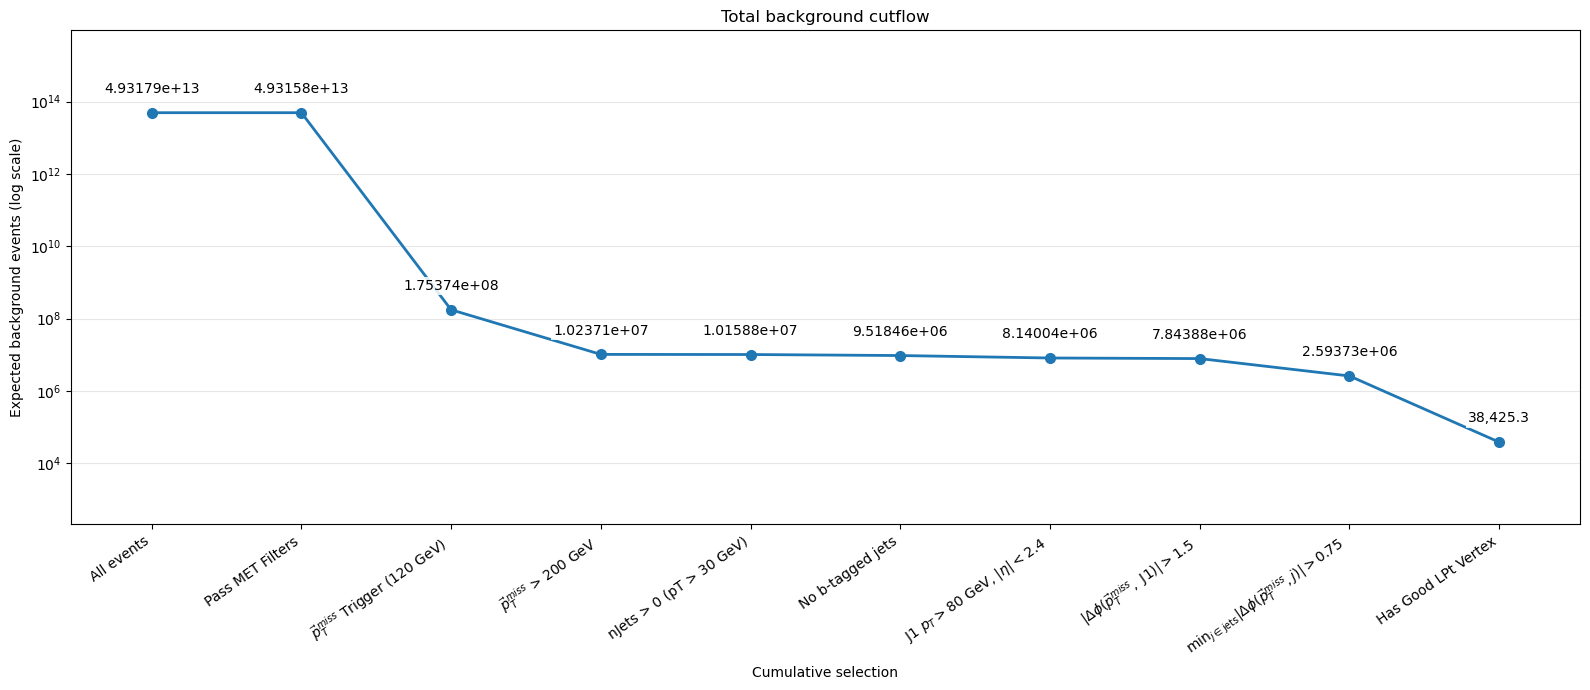

In [3]:
fig, ax = plt.subplots(figsize=(16, 7))
x = list(range(len(stages)))
ax.plot(x, yields, marker="o", linewidth=2, markersize=7, color="tab:blue")

use_log = all(value > 0 for value in yields)
if use_log:
    ax.set_yscale("log")

for position, value in zip(x, yields):
    ax.annotate(
        f"{value:,.6g}", (position, value), xytext=(0, 12),
        textcoords="offset points", ha="center", va="bottom", fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5),
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=10)
ax.set_ylabel("Expected background events" + (" (log scale)" if use_log else ""))
ax.set_xlabel("Cumulative selection")
ax.set_title("Total background cutflow")
ax.grid(axis="y", which="major", alpha=0.3)
ax.margins(x=0.06, y=0.25)
fig.tight_layout()
plt.show()


## Compare background and individual signal efficiencies

The background cells above are unchanged. Run them first. This section reads `signal.coffea` from the same directory as the background file and draws one curve per signal sample alongside total background.

Each curve is divided by its own `all` value, making the initial point 100%. Later points are cumulative percentages, not efficiencies relative to the preceding cut. Signal uses its own full-stream results for every cut; no slim files are needed. Signal samples are not added or averaged. The background curve remains weighted by expected yield across background samples.

The stored cut IDs must match. IDs alone cannot prove that the physics selections were identical: produce signal and background using the same cut configuration. A warning is shown if the saved cut descriptions differ. No files are saved automatically.


In [4]:
import warnings

signal_path = coffea_path.with_name("signal.coffea")
if not signal_path.is_file():
    raise FileNotFoundError(signal_path)
signal_loaded = util.load(str(signal_path))
signal_output = signal_loaded[0] if isinstance(signal_loaded, tuple) else signal_loaded
if not isinstance(signal_output, dict) or "cutflow" not in signal_output:
    raise ValueError("Expected signal output containing cutflow.")

# Weighted surviving fractions avoid dependence on signal cross section.
# Normalizing these fractions to 'all' gives the same percentages as
# cutflow_cts when its initial yield is nonzero.
signal_cutflows = signal_output["cutflow"]
signal_samples = sorted(signal_cutflows)
if not signal_samples or any(not name.startswith("sig_") for name in signal_samples):
    raise ValueError("Expected one or more signal-only samples with names starting sig_.")

initial_index = stages.index("all")
background_initial = yields[initial_index]
if not math.isfinite(background_initial) or background_initial <= 0:
    raise ValueError("Initial total background yield must be finite and positive.")
background_percentages = [100.0 * value / background_initial for value in yields]

signal_percentages = {}
for name in signal_samples:
    values = signal_cutflows[name]
    saved_cut_ids = {key for key in values if key.startswith("cut") and key[3:].isdigit()}
    if saved_cut_ids != set(cut_ids):
        raise ValueError(f"Signal/background cut IDs differ for {name}: {sorted(saved_cut_ids)}")
    missing = [stage for stage in stages if stage not in values]
    if missing:
        raise ValueError(f"Missing signal stages {missing} for {name}.")
    initial = float(values["all"])
    if not math.isfinite(initial) or initial <= 0:
        raise ValueError(f"Initial weighted signal fraction must be finite and positive for {name}.")
    percentages = [100.0 * float(values[stage]) / initial for stage in stages]
    if not all(math.isfinite(value) for value in percentages):
        raise ValueError(f"Non-finite signal percentage for {name}.")
    signal_percentages[name] = percentages

for stage in cut_ids:
    bkg_descriptions = output.get("cutDesc_slim", {}) if stage in ("cut1", "cut2") else output.get("cutDesc", {})
    bkg_description = str(bkg_descriptions.get(stage, "")).split("@")[0].strip()
    sig_description = str(signal_output.get("cutDesc", {}).get(stage, "")).split("@")[0].strip()
    if bkg_description != sig_description:
        warnings.warn(f"Check selection compatibility for {stage}: background={bkg_description!r}, signal={sig_description!r}")

print(f"Loaded {len(signal_samples)} signal samples from {signal_path}")


FileNotFoundError: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/SlimPlusMerged2026/signal.coffea

In [ ]:
# Each curve starts at 100%; the background calculation above is unchanged.
curves = {"Total background": background_percentages, **signal_percentages}
x = list(range(len(stages)))
fig, ax = plt.subplots(figsize=(18, 8))

# Use log scale for positive percentages. If zeros or negative weighted
# yields occur, symlog displays them without replacing any saved value.
all_positive = all(value > 0 for values in curves.values() for value in values)
if all_positive:
    ax.set_yscale("log")
    scale_label = "log scale"
else:
    ax.set_yscale("symlog", linthresh=0.01)
    scale_label = "symlog scale; linear within +/-0.01%"
    print("Zero/negative percentages found: using symlog so every value stays visible.")

colors = plt.get_cmap("tab20")
for index, (name, values) in enumerate(curves.items()):
    is_background = index == 0
    color = "black" if is_background else colors((index - 1) % 20)
    ax.plot(
        x, values, label=name, color=color, marker="o" if is_background else "s",
        linewidth=2.5 if is_background else 1.5, markersize=6,
        linestyle="-" if is_background else "--",
    )
    for position, value in zip(x, values):
        # The shared initial 100% point is labeled only once.
        if position == initial_index and not is_background:
            continue
        offset = 12 if is_background else (12 + 12 * ((index - 1) % 3)) * (-1 if index % 2 else 1)
        ax.annotate(
            f"{value:.3g}%", (position, value), xytext=(0, offset),
            textcoords="offset points", ha="center",
            va="bottom" if offset > 0 else "top", fontsize=12, color=color,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
        )

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=12)
ax.tick_params(axis="both", which="both", labelsize=12)
ax.set_ylabel(f"Remaining (% of each curve's initial value; {scale_label})", fontsize=12)
ax.set_xlabel("Selection step (all previous cuts included)", fontsize=12)
ax.set_title("Background and signal cutflows — All events = 100%", fontsize=12)
ax.legend(title="Samples", fontsize=12, title_fontsize=12, loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(axis="y", which="major", alpha=0.3)
ax.margins(x=0.06, y=0.25)
fig.tight_layout()
plt.show()
